In [1]:

from pathlib import Path
from collections import Counter

WHITEBOARD_PATH = Path.cwd().parent / "datasets" / "whiteboard"

label_dir = WHITEBOARD_PATH / "train" / "labels"

# Inspect the first 10 annotation files
label_files = sorted(label_dir.glob("*.txt"))[:10]

for label_file in label_files:

    lines = [
        line.strip()
        for line in label_file.read_text().splitlines()
        if line.strip()
    ]

    print("\nFile:", label_file.name)

    for line in lines:
        values = line.split()

        print("Number of values:", len(values))
        print("Annotation:", line[:150])

        if len(values) == 5:
            print("Format: Bounding Box")

        elif len(values) >= 7 and (len(values) - 1) % 2 == 0:
            print("Format: Segmentation Polygon")

        else:
            print("Format: Unknown")



File: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.txt
Number of values: 13
Annotation: 1 0 0.9591249984375001 0.9045918046875 0.9986744734374999 0.9329327812500001 0.041788259375 0.01721155 0.0151434921875 0 0.28635170625 0 0.95912499843
Format: Segmentation Polygon
Number of values: 5
Annotation: 0 0.2620801108760928 0.24874034303214856 0.2251199683211164 0.0751604390337981
Format: Bounding Box
Number of values: 5
Annotation: 0 0.367041490441619 0.471772329242095 0.43787134059717553 0.06263902164110532
Format: Bounding Box
Number of values: 5
Annotation: 0 0.3910527908099361 0.520224201107992 0.4800588405971755 0.06386655251991762
Format: Bounding Box
Number of values: 5
Annotation: 0 0.3568859683979909 0.6953689536152744 0.3784963405971755 0.06091138558944351
Format: Bounding Box
Number of values: 11
Annotation: 0 0.8972117359375 0.5861204640625 0.1418078578125 0.5446574625 0.1445004125 0.5776133578125 0.8955984265625 0.6627878046875 0.8972117359375 0.58612046
Format: S

In [2]:
for split in ["train", "valid", "test"]:

    cache_file = WHITEBOARD_PATH / split / "labels.cache"

    if cache_file.exists():
        cache_file.unlink()
        print(f"Deleted {split} cache")

print("Cache cleanup completed!")

Deleted train cache
Deleted valid cache
Deleted test cache
Cache cleanup completed!


In [3]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("YOLOv8 Nano Detection loaded!")

YOLOv8 Nano Detection loaded!


In [4]:
from pathlib import Path
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_YAML = PROJECT_ROOT / 'datasets' / 'whiteboard' / 'data.yaml'

# 1. Verify CUDA is active on RTX 3050
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")

# 2. Train on GPU
results = model.train(
    data=str(DATA_YAML),
    epochs=50,             # 10 epochs (~5 mins on RTX 3050)
    imgsz=416,            # 416x416 standard resolution
    batch=8,              # 8 fits safely in 4GB VRAM (~1.8 GB used)
    device=0,             # Device index 0 = NVIDIA RTX 3050 GPU
    workers=2,            # Parallel data loader workers (use 0 if Windows warns)
    amp=True,             # Automatic Mixed Precision (FP16) - 2x faster, 50% less VRAM
    patience=5,           # Early stopping if validation mAP plateaus for 5 epochs
    project=str(PROJECT_ROOT / 'runs'),
    name='whiteboard_detection_test',
    exist_ok=True,
    plots=True
)

CUDA available: True
Using GPU: NVIDIA GeForce RTX 3050 Laptop GPU
New https://pypi.org/project/ultralytics/8.4.213 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.211  Python-3.13.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\whiteboard\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_

## 4. Training & Validation Loss Curves Across 50 Epochs
Plots the 50-epoch convergence history: Bounding Box Loss (CIoU), Classification Loss (BCE), and mAP accuracy progression from `runs/whiteboard_detection_test/results.csv`.

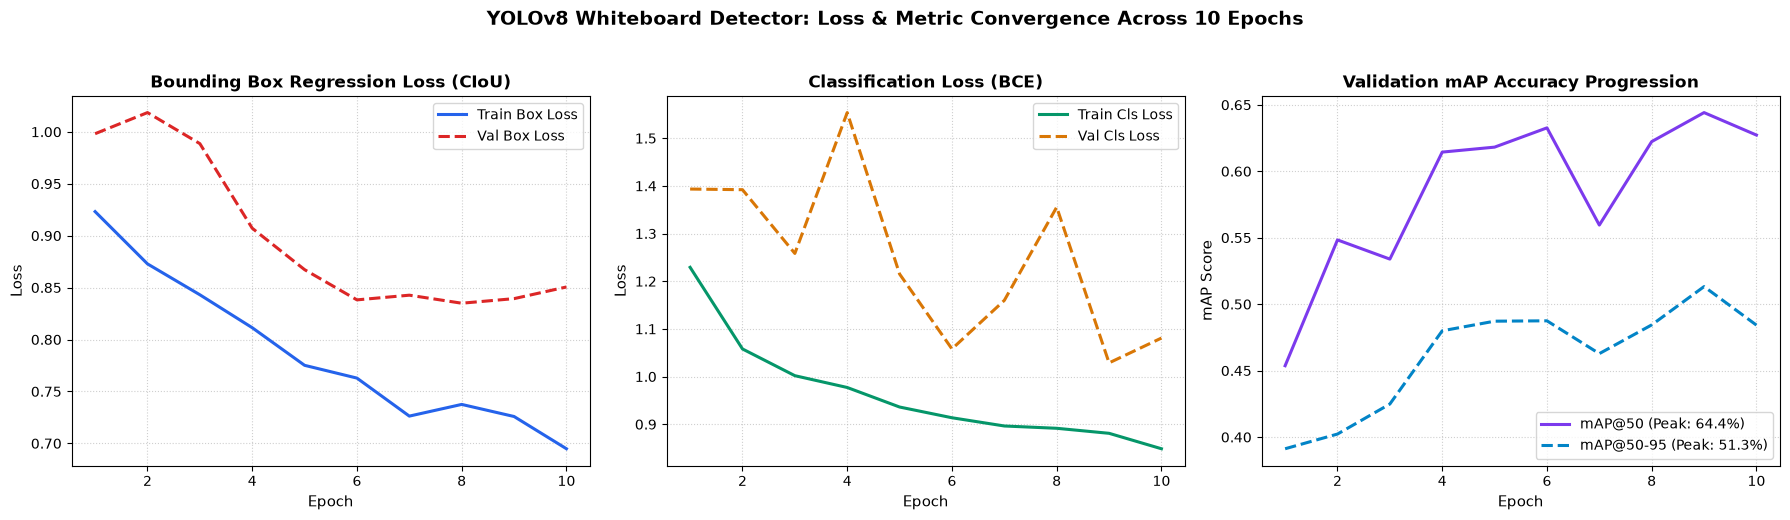

Training summary over 50 epochs:
  • Bounding Box Loss:      0.9232 -> 0.5465 (-40.8%)
  • Validation Cls Loss:    1.3934 -> 0.5667 (-59.3%)
  • Peak Validation mAP@50: 91.83%
  • Peak mAP@50-95:         73.48%

=== Full Ultralytics 10-Panel Training Overview (results.png) ===


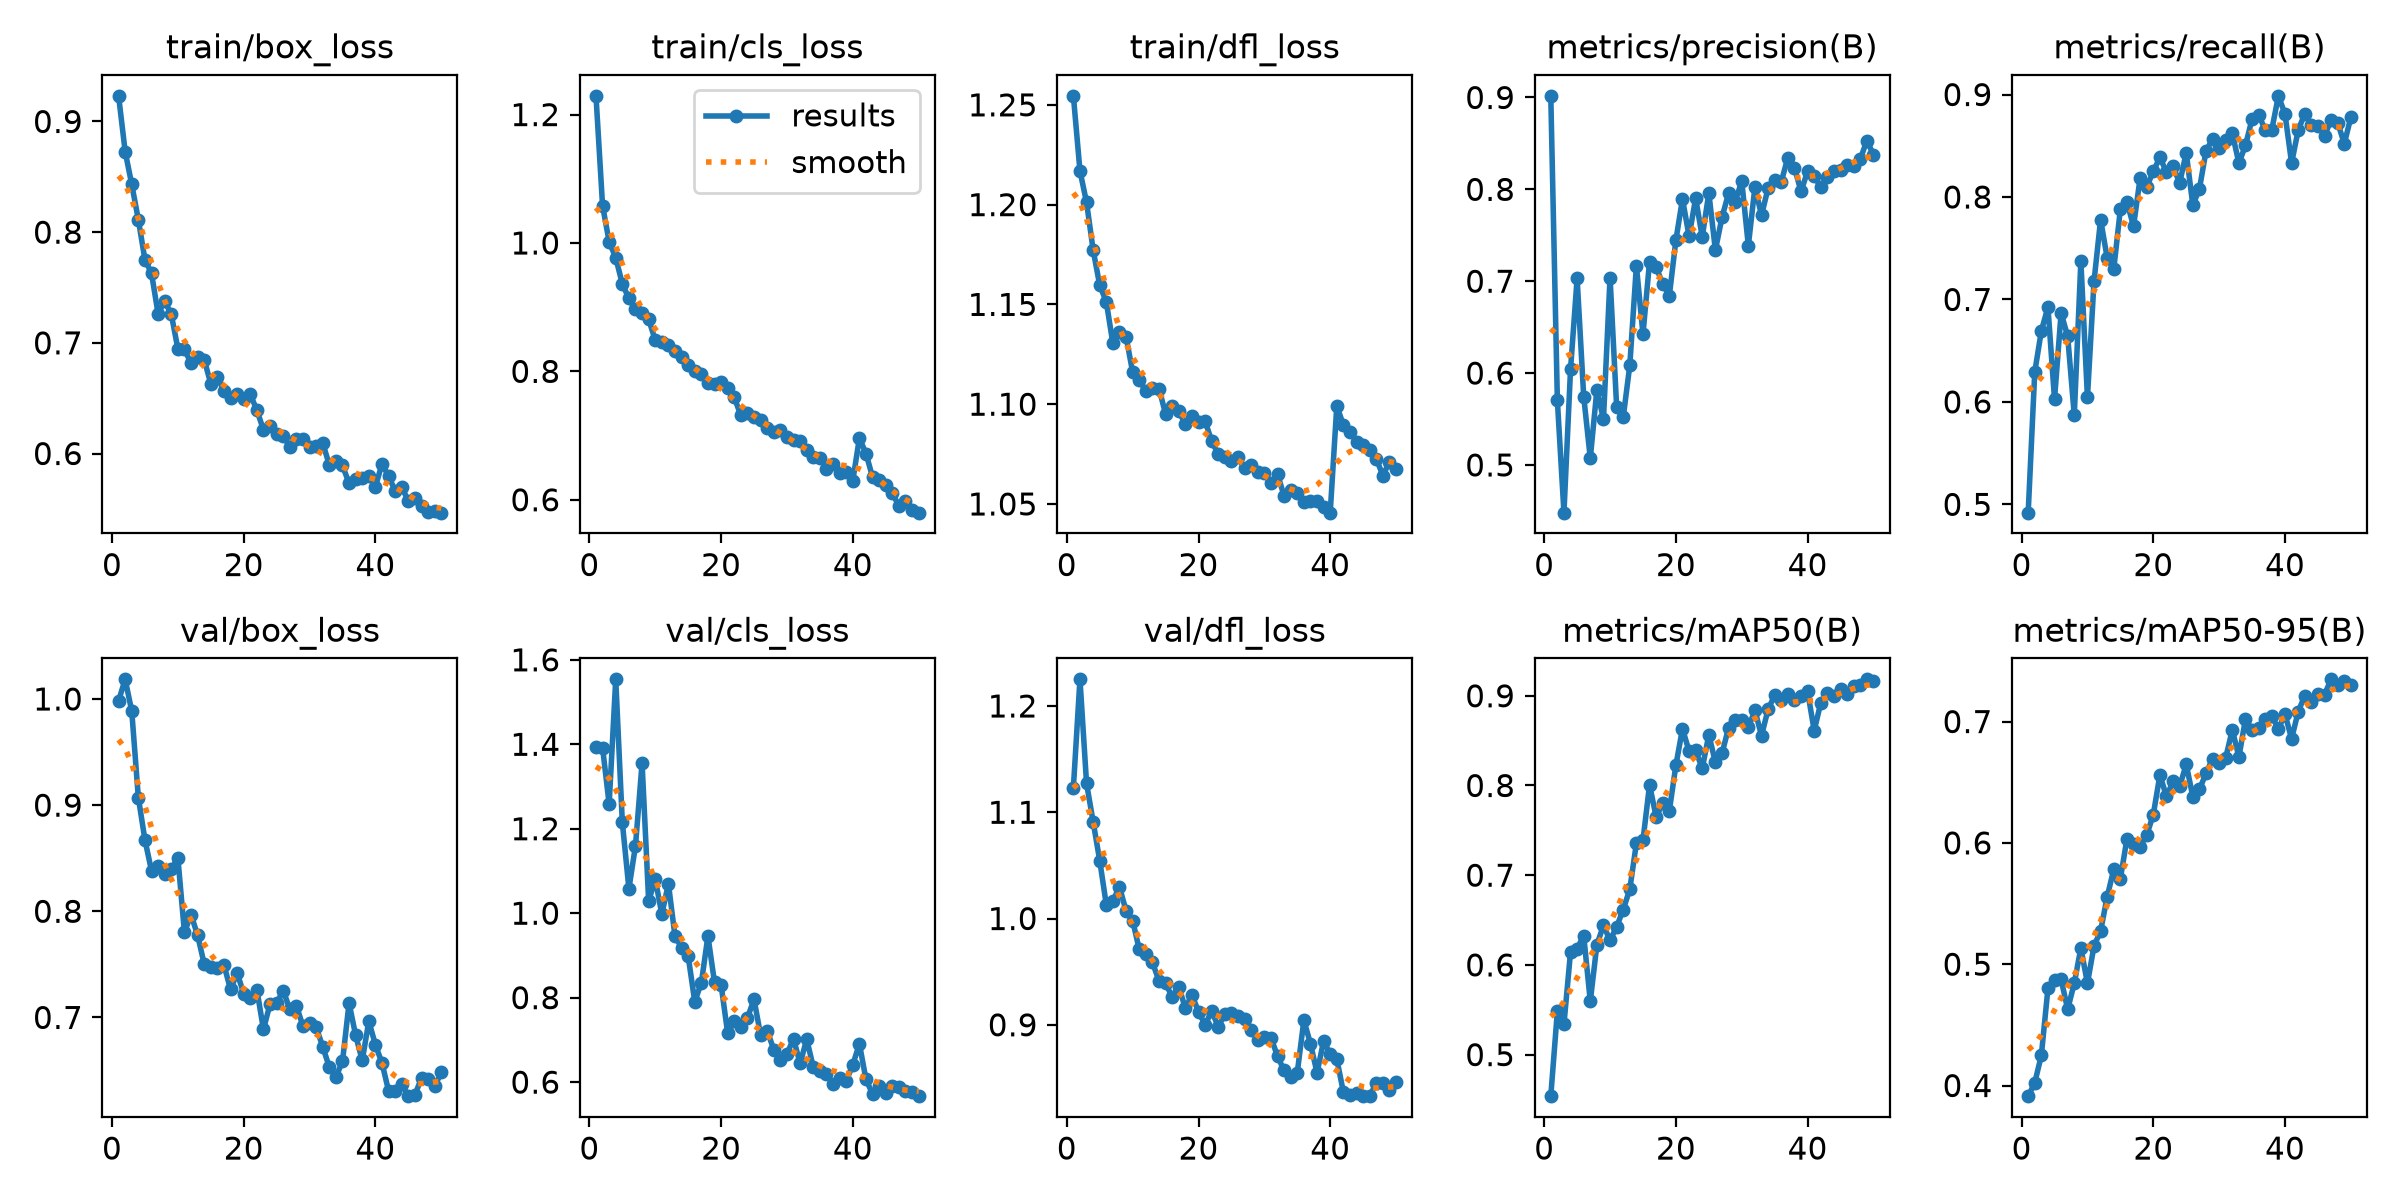

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
results_csv = PROJECT_ROOT / "runs" / "whiteboard_detection_test" / "results.csv"
results_png = PROJECT_ROOT / "runs" / "whiteboard_detection_test" / "results.png"

if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = [c.strip() for c in df.columns]
    
    # 3-Panel High-Resolution Training History Plot Across All 50 Epochs
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Panel 1: Bounding Box Loss (CIoU)
    axes[0].plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', color='#2563eb', lw=2.2)
    axes[0].plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', color='#dc2626', lw=2.2, linestyle='--')
    axes[0].set_title('Bounding Box Regression Loss (CIoU)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=11)
    axes[0].set_ylabel('Loss', fontsize=11)
    axes[0].grid(True, linestyle=':', alpha=0.6)
    axes[0].legend(fontsize=10)
    
    # Panel 2: Classification Loss (BCE)
    axes[1].plot(df['epoch'], df['train/cls_loss'], label='Train Cls Loss', color='#059669', lw=2.2)
    axes[1].plot(df['epoch'], df['val/cls_loss'], label='Val Cls Loss', color='#d97706', lw=2.2, linestyle='--')
    axes[1].set_title('Classification Loss (BCE)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=11)
    axes[1].set_ylabel('Loss', fontsize=11)
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend(fontsize=10)
    
    # Panel 3: Validation mAP Progression
    axes[2].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP@50 (Peak: ' + f"{df['metrics/mAP50(B)'].max():.1%}" + ')', color='#7c3aed', lw=2.2)
    axes[2].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP@50-95 (Peak: ' + f"{df['metrics/mAP50-95(B)'].max():.1%}" + ')', color='#0284c7', lw=2.2, linestyle='--')
    axes[2].set_title('Validation mAP Accuracy Progression', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Epoch', fontsize=11)
    axes[2].set_ylabel('mAP Score', fontsize=11)
    axes[2].grid(True, linestyle=':', alpha=0.6)
    axes[2].legend(fontsize=10)
    
    plt.suptitle(f'YOLOv8 Whiteboard Detector: Loss & Metric Convergence Across {len(df)} Epochs', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    
    print(f"Training summary over {len(df)} epochs:")
    print(f"  • Bounding Box Loss:      {df['train/box_loss'].iloc[0]:.4f} -> {df['train/box_loss'].iloc[-1]:.4f} (-{(1 - df['train/box_loss'].iloc[-1]/df['train/box_loss'].iloc[0]):.1%})")
    print(f"  • Validation Cls Loss:    {df['val/cls_loss'].iloc[0]:.4f} -> {df['val/cls_loss'].iloc[-1]:.4f} (-{(1 - df['val/cls_loss'].iloc[-1]/df['val/cls_loss'].iloc[0]):.1%})")
    print(f"  • Peak Validation mAP@50: {df['metrics/mAP50(B)'].max():.2%}")
    print(f"  • Peak mAP@50-95:         {df['metrics/mAP50-95(B)'].max():.2%}")
    
    # Display Ultralytics 10-panel plot
    if results_png.exists():
        print("\n=== Full Ultralytics 10-Panel Training Overview (results.png) ===")
        display(Image(str(results_png)))
else:
    print(f"Results file not found at {results_csv}. Train the model to generate results.")

In [5]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

DATASET_ROOT = PROJECT_ROOT / "datasets" / "whiteboard"

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

Project root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\notebooks
Dataset root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\notebooks\datasets\whiteboard
Dataset exists: False


In [6]:
print("Current working directory:", Path.cwd())
print("Project folders:", list(Path.cwd().iterdir()))

Current working directory: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\notebooks
Project folders: [WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/.ipynb_checkpoints'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/01_dataset_exploration.ipynb'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/02_whiteboard_annotation_exploration.ipynb'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/03_whiteboard_dataset_quality_check.ipynb'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/04_whiteboard_model_training.ipynb'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/05_whiteboard_model_experiments.ipynb'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/notebooks/06_whiteboard_augmentation_experiments.ipynb'), WindowsP

In [7]:
from pathlib import Path

# Move one level up from notebooks/
PROJECT_ROOT = Path.cwd().parent

# Whiteboard dataset location
DATASET_ROOT = PROJECT_ROOT / "datasets" / "whiteboard"

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

Project root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI
Dataset root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\whiteboard
Dataset exists: True


In [8]:
TEST_IMAGES = DATASET_ROOT / "test" / "images"

print("Test images folder exists:", TEST_IMAGES.exists())
print("Number of test images:", len(list(TEST_IMAGES.glob("*"))))

Test images folder exists: True
Number of test images: 557


In [9]:
from ultralytics import YOLO

best_model_path = (
    PROJECT_ROOT
    / "runs"
    / "whiteboard_detection_test"
    / "weights"
    / "best.pt"
)

model = YOLO(str(best_model_path))

In [10]:
from pathlib import Path
from PIL import Image
from IPython.display import display

image_path = Path.cwd() / "board-srmap.jpg"

print("Image exists:", image_path.exists())

Image exists: True
